# ARIMA for Time Series Forecasting

This notebook demonstrates a complete, non-seasonal ARIMA workflow: stationarity assessment, differencing, ACF/PACF, model fitting, order comparison, chronological validation, residual diagnostics, forecast intervals and baseline evaluation.

**Learning objectives**
- Understand AR, I and MA components and the `(p,d,q)` order.
- Assess stationarity using plots, ADF and KPSS tests.
- Use ACF/PACF as guides for candidate orders.
- Fit and compare ARIMA models with `statsmodels`.
- Evaluate out-of-sample forecasts and diagnose residuals.

ARIMA is non-seasonal. Seasonal patterns are handled explicitly by SARIMA/SARIMAX, the next topic in this series.

## 1. What is ARIMA?

**ARIMA** means **AutoRegressive Integrated Moving Average**.

- **AR(p):** uses previous observations (lags) to explain the current value.
- **I(d):** differences the series `d` times to help achieve stationarity.
- **MA(q):** uses previous forecast errors (not a simple rolling average) to explain the current value.

The model is written as `ARIMA(p,d,q)`.

For first differencing, `W_t = Y_t - Y_(t-1)`. The differenced series can then be represented by an ARMA process:

`W_t = c + φ₁W_(t-1) + ... + φₚW_(t-p) + ε_t + θ₁ε_(t-1) + ... + θqε_(t-q)`

`p` = number of AR lags; `d` = differencing order; `q` = number of MA error lags. Software and textbook conventions can use different signs for MA terms.

Example: ARIMA(1,1,1) differences the original series once and includes one AR lag and one MA error lag.

## 2. Install and import packages

Install if required: `pip install numpy pandas matplotlib statsmodels scikit-learn seaborn`

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_error, mean_squared_error

np.random.seed(42)
plt.rcParams["figure.figsize"] = (12, 5)

## 3. Create a sample monthly demand series

We create a series with an upward trend and autocorrelated errors. This is a teaching dataset, not real customer demand. We intentionally keep the example non-seasonal so that standard ARIMA is the focus.

2016-01-01    250.000000
2016-02-01    251.546456
2016-03-01    264.496755
2016-04-01    291.722351
2016-05-01    279.816167
Freq: MS, Name: Demand, dtype: float64

count    120.000000
mean     352.682585
std       69.397998
min      216.428608
25%      289.187159
50%      356.647631
75%      408.412274
max      491.054638
Name: Demand, dtype: float64

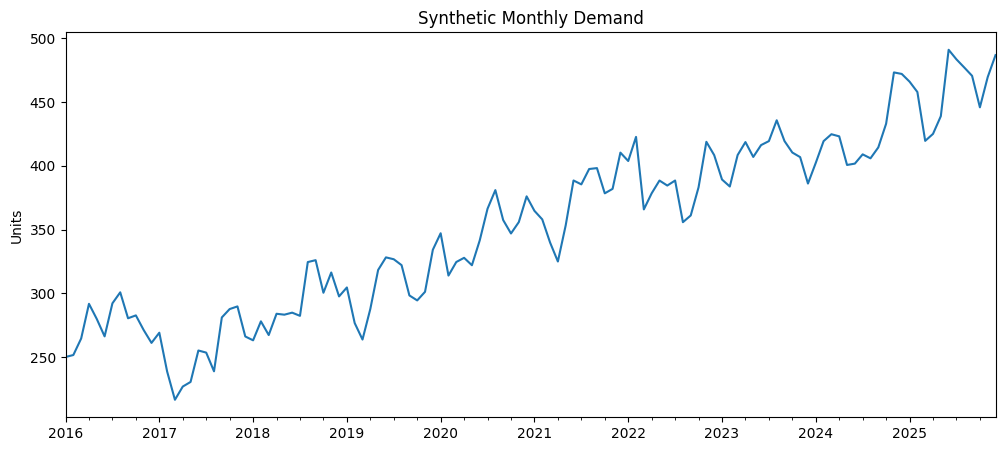

In [2]:
n = 120
dates = pd.date_range("2016-01-01", periods=n, freq="MS")
noise = np.random.normal(0, 18, n)
errors = np.zeros(n)
for t in range(1, n):
    errors[t] = 0.55 * errors[t-1] + noise[t] + 0.25 * noise[t-1]
demand = 250 + 1.8*np.arange(n) + errors
y = pd.Series(demand, index=dates, name="Demand").clip(lower=20)

display(y.head())
display(y.describe())
y.plot(title="Synthetic Monthly Demand", ylabel="Units")
plt.show()

## 4. Stationarity and differencing

A weakly stationary series has a broadly stable mean and variance, and autocovariance that depends on lag rather than calendar time. Trend and changing levels can violate stationarity.

First difference: `ΔY_t = Y_t - Y_(t-1)`

Second difference: `Δ²Y_t = ΔY_t - ΔY_(t-1)`

The ADF test has a unit-root/non-stationarity null; a small p-value is evidence against that null. KPSS has a stationarity null; a small p-value is evidence against stationarity. Their null hypotheses differ, so they can be used as complementary diagnostics. Neither test should mechanically determine `d`.

In [3]:
def stationarity_report(series, kpss_regression="c"):
    x = pd.Series(series).dropna()
    a = adfuller(x, autolag="AIC")
    k = kpss(x, regression=kpss_regression, nlags="auto")
    print(f"ADF statistic={a[0]:.4f}, p-value={a[1]:.4f}")
    print("ADF small p-value: evidence against a unit root.")
    print(f"KPSS statistic={k[0]:.4f}, p-value={k[1]:.4f}")
    print("KPSS small p-value: evidence against the stationarity null.")

stationarity_report(y, kpss_regression="ct")

ADF statistic=-0.0917, p-value=0.9503
ADF small p-value: evidence against a unit root.
KPSS statistic=0.0775, p-value=0.1000
KPSS small p-value: evidence against the stationarity null.


/var/folders/g9/ptbc1d_n3z32lgnjtg4zvwqr0000gp/T/ipykernel_82191/3551398710.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  k = kpss(x, regression=kpss_regression, nlags="auto")


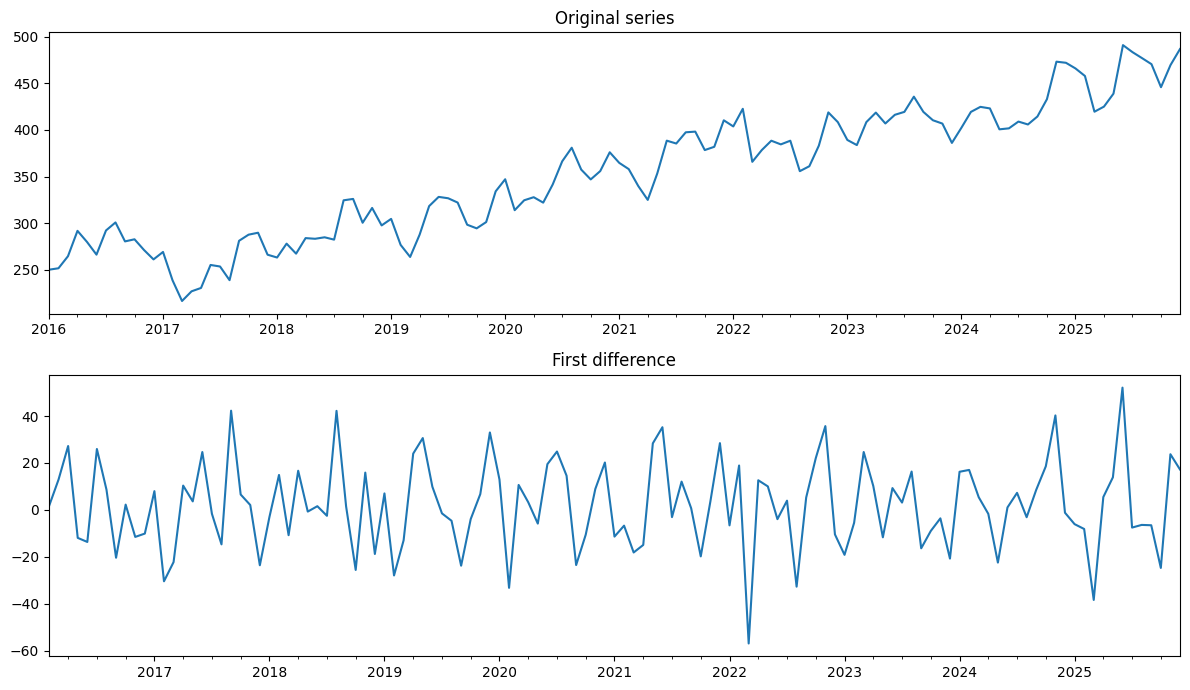

ADF statistic=-6.4962, p-value=0.0000
ADF small p-value: evidence against a unit root.
KPSS statistic=0.0495, p-value=0.1000
KPSS small p-value: evidence against the stationarity null.


/var/folders/g9/ptbc1d_n3z32lgnjtg4zvwqr0000gp/T/ipykernel_82191/3551398710.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  k = kpss(x, regression=kpss_regression, nlags="auto")


In [4]:
dy = y.diff().dropna()
fig, ax = plt.subplots(2, 1, figsize=(12, 7))
y.plot(ax=ax[0], title="Original series")
dy.plot(ax=ax[1], title="First difference")
plt.tight_layout()
plt.show()
stationarity_report(dy)

## 5. ACF and PACF

- **ACF:** correlation between the series and its lagged values.
- **PACF:** correlation at a lag after accounting for shorter lags.

Identification heuristics:
- AR(p): PACF may cut off after p lags while ACF tails off.
- MA(q): ACF may cut off after q lags while PACF tails off.
- ARMA: both may tail off.

These are guidelines, not rules. Real plots can be ambiguous. Use them to create candidate models, then compare validation forecasts and residual diagnostics.

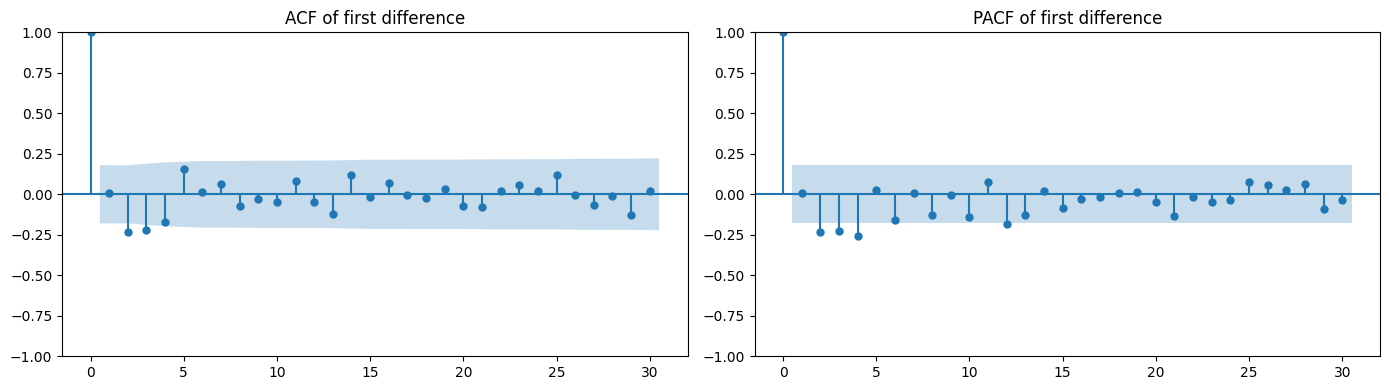

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(dy, lags=30, ax=ax[0])
plot_pacf(dy, lags=30, method="ywm", ax=ax[1])
ax[0].set_title("ACF of first difference")
ax[1].set_title("PACF of first difference")
plt.tight_layout()
plt.show()

## 6. Chronological train / validation / test split

Do not randomly shuffle time series observations. Train on the past and evaluate on later periods.

We use 70% training, 15% validation and 15% test. The validation period is for model selection; the test period is held back for final evaluation.

Rows: 84 18 18


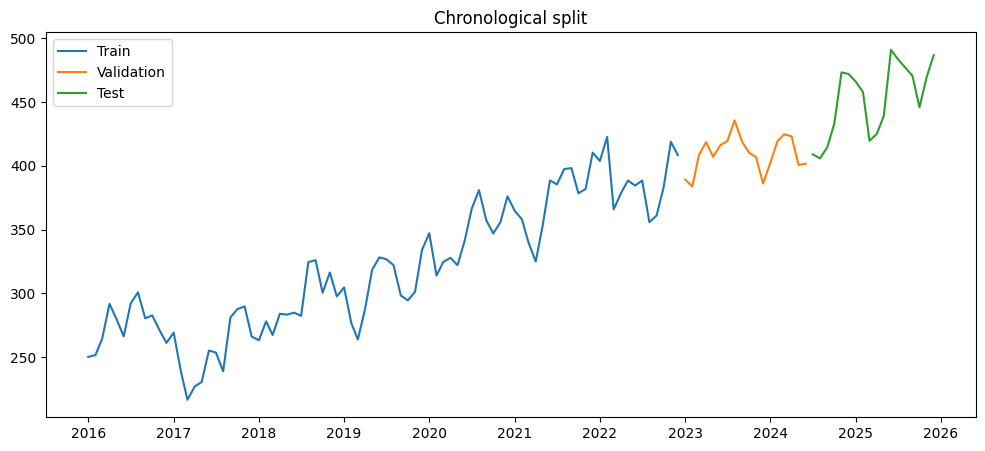

In [6]:
n = len(y)
i_train, i_valid = int(n*.70), int(n*.85)
train, valid, test = y.iloc[:i_train], y.iloc[i_train:i_valid], y.iloc[i_valid:]
print("Rows:", len(train), len(valid), len(test))
plt.plot(train, label="Train")
plt.plot(valid, label="Validation")
plt.plot(test, label="Test")
plt.legend()
plt.title("Chronological split")
plt.show()

## 7. Fit an initial ARIMA model

`statsmodels.tsa.arima.model.ARIMA` estimates ARIMA models. The `order` argument is `(p,d,q)`. Start with a few plausible specifications based on the data and diagnostics. There is no universally best order.

We start with ARIMA(1,1,1). The default trend handling is used here; whether a constant or drift term is appropriate depends on the differencing order and data-generating process.

In [7]:
initial_fit = ARIMA(train, order=(1, 1, 1)).fit()
print(initial_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                 Demand   No. Observations:                   84
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -359.905
Date:                Wed, 25 Nov 2026   AIC                            725.810
Time:                        10:12:02   BIC                            733.066
Sample:                    01-01-2016   HQIC                           728.725
                         - 12-01-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6134      0.265      2.312      0.021       0.093       1.134
ma.L1         -0.8228      0.181     -4.540      0.000      -1.178      -0.468
sigma2       341.0737     56.622      6.024      0.0

## 8. Compare candidate orders on validation data

AIC and BIC balance model fit and complexity, but they do not replace out-of-sample forecast evaluation. We fit a small candidate grid on training data and compare forecasts on validation data.

Metrics:
- MAE: average absolute error in demand units.
- RMSE: square-root of average squared error; penalizes larger errors.
- WMAPE: total absolute error divided by total absolute actuals.
- Bias: average forecast minus actual; positive means over-forecasting under this convention.

For production use, rolling-origin backtesting is often more robust than a single validation window.

In [8]:
def metrics(actual, pred):
    a, p = np.asarray(actual, float), np.asarray(pred, float)
    denom = np.sum(np.abs(a))
    return {
        "MAE": mean_absolute_error(a, p),
        "RMSE": np.sqrt(mean_squared_error(a, p)),
        "WMAPE_%": np.sum(np.abs(a-p))/denom*100 if denom else np.nan,
        "Bias": np.mean(p-a)
    }

orders = [(0,1,1), (1,1,0), (1,1,1), (2,1,0),
          (0,1,2), (2,1,1), (1,1,2), (2,1,2)]
rows = []
for order in orders:
    try:
        fit = ARIMA(train, order=order).fit()
        pred = fit.forecast(steps=len(valid))
        rows.append({"order": order, "AIC": fit.aic, "BIC": fit.bic,
                     **metrics(valid, pred)})
    except Exception as e:
        print("Could not fit", order, e)

comparison = pd.DataFrame(rows).sort_values("WMAPE_%")
display(comparison)
best_order = tuple(comparison.iloc[0]["order"])
print("Selected order:", best_order)

,order,AIC,BIC,MAE,RMSE,WMAPE_%,Bias
0,"(0, 1, 1)",729.146453,733.984134,11.168882,13.673987,2.726610,-0.771687
1,"(1, 1, 0)",729.203462,734.041144,11.169345,13.684333,2.726723,-0.927295
3,"(2, 1, 0)",727.063119,734.319641,11.966724,14.442467,2.921383,-5.635980
4,"(0, 1, 2)",723.941473,731.197995,16.856987,19.338637,4.115222,-13.748414
2,"(1, 1, 1)",725.809501,733.066022,17.070663,19.334337,4.167386,-12.482001
6,"(1, 1, 2)",724.926749,734.602111,18.509246,20.929532,4.518581,-15.448131
5,"(2, 1, 1)",724.571371,734.246733,18.872825,21.402845,4.607340,-16.321139
7,"(2, 1, 2)",726.525185,738.619388,18.925144,21.480857,4.620112,-16.483827


Selected order: (0, 1, 1)


## 9. Final test evaluation

After choosing an order, refit using train plus validation. Then evaluate once on the untouched test set. This gives a more honest estimate of performance than repeatedly tuning against test data.

,Actual,Forecast
2024-07-01,408.999313,401.719725
2024-08-01,405.886416,401.719725
2024-09-01,414.454138,401.719725
2024-10-01,433.036906,401.719725
2024-11-01,473.289873,401.719725
2024-12-01,472.099667,401.719725
2025-01-01,466.046324,401.719725
2025-02-01,457.924429,401.719725
2025-03-01,419.575547,401.719725
2025-04-01,425.054831,401.719725


{'MAE': 50.5054168716751, 'RMSE': np.float64(57.61769367410434), 'WMAPE_%': np.float64(11.168201893246765), 'Bias': np.float64(-50.5054168716751)}


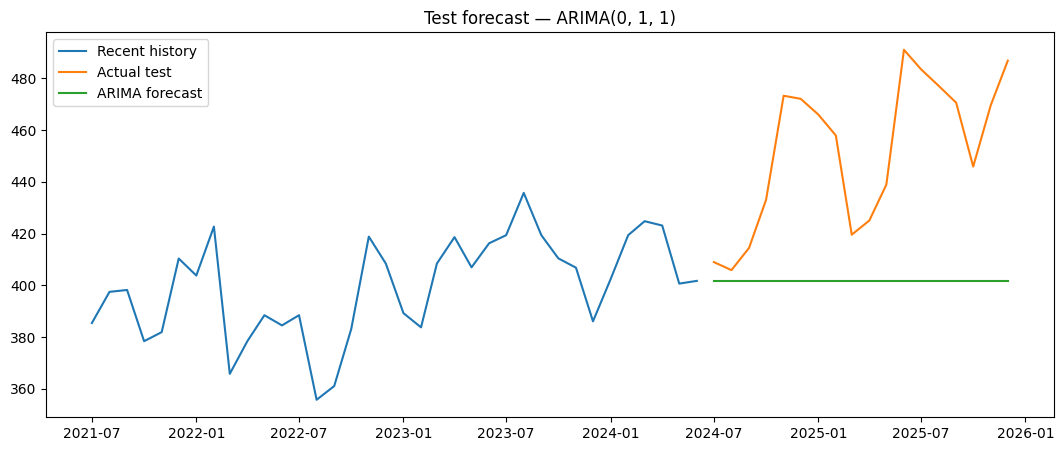

In [9]:
train_valid = pd.concat([train, valid])
final_fit = ARIMA(train_valid, order=best_order).fit()
test_pred = final_fit.forecast(steps=len(test))
display(pd.DataFrame({"Actual": test, "Forecast": test_pred}))
print(metrics(test, test_pred))

plt.figure(figsize=(13,5))
plt.plot(train_valid.index[-36:], train_valid.iloc[-36:], label="Recent history")
plt.plot(test, label="Actual test")
plt.plot(test_pred, label="ARIMA forecast")
plt.title(f"Test forecast — ARIMA{best_order}")
plt.legend()
plt.show()

## 10. Residual diagnostics

Residuals are the differences between observations and fitted values. A useful model should leave no obvious predictable structure.

Inspect:
- Residuals over time for trend, changing variance or outliers.
- Residual ACF for remaining autocorrelation.
- Residual distribution for skewness or heavy tails.
- Ljung-Box test for joint autocorrelation across selected lags.

The Ljung-Box null is that the specified group of residual autocorrelations is zero. A small p-value suggests remaining autocorrelation. Residuals need not be perfectly normal for point forecasts to be useful, but distributional assumptions matter for intervals.

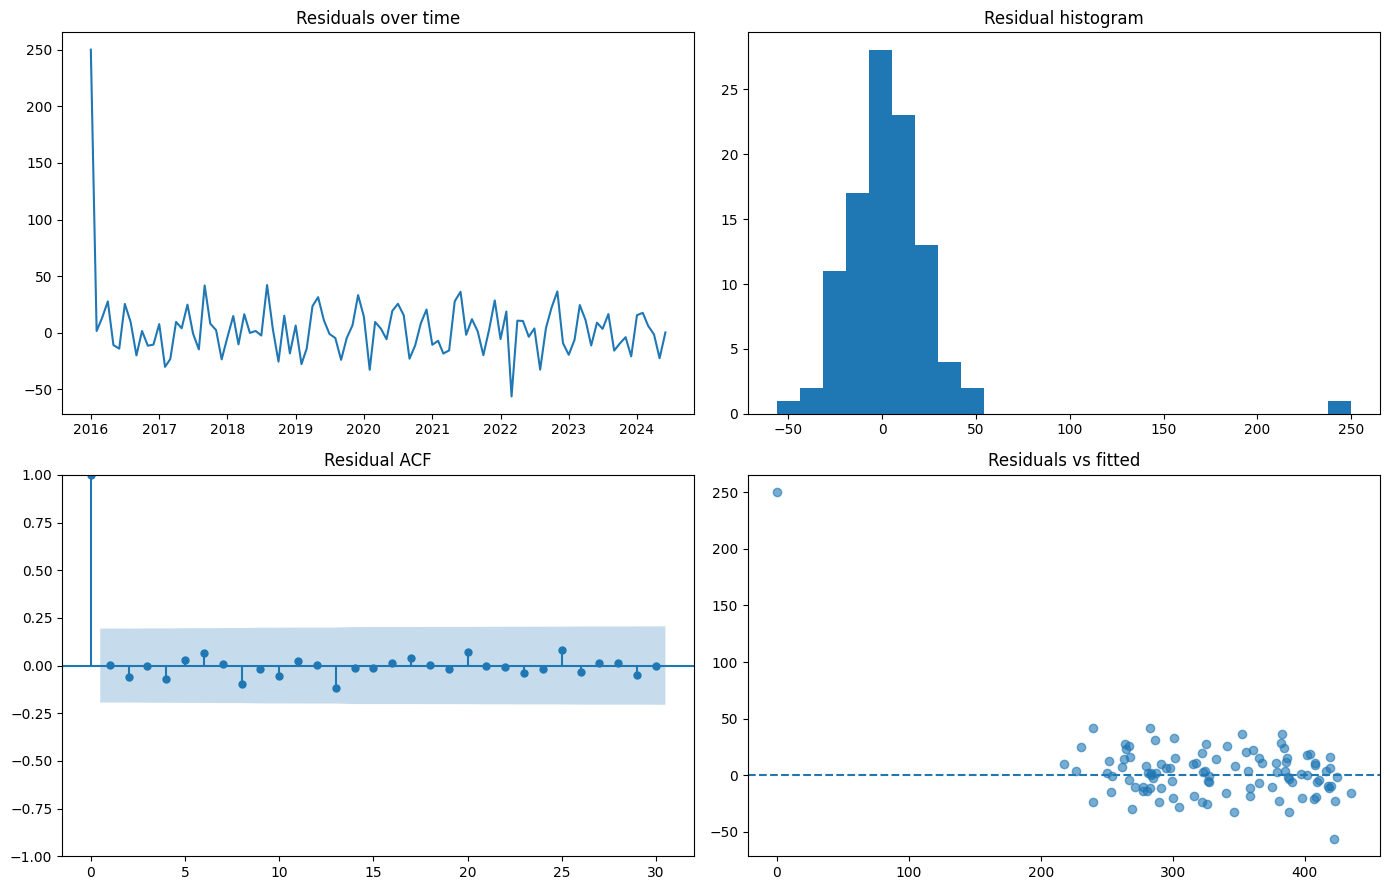

,lb_stat,lb_pvalue
10,2.918380,0.983280
20,5.721544,0.999225


In [10]:
resid = final_fit.resid
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
ax[0,0].plot(resid); ax[0,0].set_title("Residuals over time")
ax[0,1].hist(resid.dropna(), bins=25); ax[0,1].set_title("Residual histogram")
plot_acf(resid.dropna(), lags=30, ax=ax[1,0])
ax[1,0].set_title("Residual ACF")
ax[1,1].scatter(final_fit.fittedvalues, resid, alpha=.6)
ax[1,1].axhline(0, linestyle="--"); ax[1,1].set_title("Residuals vs fitted")
plt.tight_layout()
plt.show()
display(acorr_ljungbox(resid.dropna(), lags=[10,20], return_df=True))

## 11. Forecast future demand with prediction intervals

`get_forecast()` returns point forecasts and model-based prediction intervals. Intervals usually widen with horizon. They are not guaranteed bounds: promotions, stockouts, structural breaks and other unexpected events can make actual uncertainty larger.

,Forecast,Lower_95,Upper_95
2024-07-01,401.719725,365.876416,437.563034
2024-08-01,401.719725,351.904490,451.534961
2024-09-01,401.719725,341.070137,462.369313
2024-10-01,401.719725,331.897183,471.542268
2024-11-01,401.719725,323.796671,479.642779
2024-12-01,401.719725,316.462366,486.977084
2025-01-01,401.719725,309.710855,493.728595
2025-02-01,401.719725,303.421979,500.017472
2025-03-01,401.719725,297.511943,505.927507
2025-04-01,401.719725,291.919558,511.519892


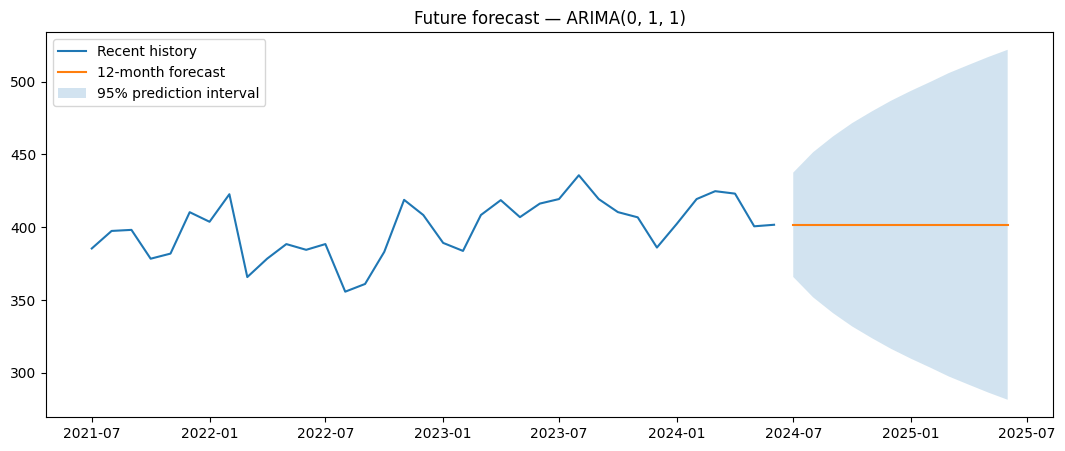

In [11]:
steps = 12
future = final_fit.get_forecast(steps=steps)
mean_forecast = future.predicted_mean
ci = future.conf_int(alpha=.05)
future_table = pd.DataFrame({
    "Forecast": mean_forecast,
    "Lower_95": ci.iloc[:,0],
    "Upper_95": ci.iloc[:,1]
})
display(future_table)

plt.figure(figsize=(13,5))
plt.plot(train_valid.iloc[-36:], label="Recent history")
plt.plot(mean_forecast, label="12-month forecast")
plt.fill_between(ci.index, ci.iloc[:,0], ci.iloc[:,1],
                 alpha=.2, label="95% prediction interval")
plt.title(f"Future forecast — ARIMA{best_order}")
plt.legend()
plt.show()

## 12. Compare against simple baselines

A complex model should demonstrate value over simple benchmarks. We compare ARIMA with:
- Naive: every future value equals the last training observation.
- Mean: every future value equals the training-period average.

Depending on the data, seasonal naive or drift may be more appropriate benchmarks.

In [12]:
naive = pd.Series(train_valid.iloc[-1], index=test.index)
mean_base = pd.Series(train_valid.mean(), index=test.index)
baseline_rows = []
for name, pred in {"Naive": naive, "Mean": mean_base,
                   f"ARIMA{best_order}": test_pred}.items():
    baseline_rows.append({"Model": name, **metrics(test, pred)})
display(pd.DataFrame(baseline_rows).sort_values("WMAPE_%"))

,Model,MAE,RMSE,WMAPE_%,Bias
0,Naive,50.495909,57.609360,11.166100,-50.495909
2,"ARIMA(0, 1, 1)",50.505417,57.617694,11.168202,-50.505417
1,Mean,117.108890,120.347388,25.896148,-117.108890


## 13. Practical considerations, strengths and limitations

**Useful when**
- A univariate series has meaningful autocorrelation.
- A modest amount of differencing makes it reasonably stationary.
- Historical dynamics remain reasonably stable.
- A statistical benchmark is needed.

**Limitations**
- Standard ARIMA does not explicitly model seasonality.
- It does not automatically include promotions, prices, holidays or weather.
- Structural breaks and outliers can damage forecasts.
- Order selection and differencing require care.
- Intermittent demand with many zeros may need specialized methods.

**Supply-chain applications**
- Item-location series with stable, non-seasonal autocorrelation.
- Aggregated product-family demand as a statistical benchmark.
- Selected operational metrics such as throughput or usage.

For highly seasonal retail demand, intermittent spare-parts demand, new products or promotion-driven demand, ARIMA may not be the best standalone method.

## 14. Common mistakes

1. Randomly splitting time series data.
2. Assuming `d=1` is always required.
3. Over-differencing.
4. Treating ACF/PACF heuristics as absolute rules.
5. Selecting only by AIC/BIC without validation.
6. Ignoring residual autocorrelation.
7. Repeatedly tuning against the test set.
8. Comparing models across different forecast horizons.
9. Confusing the MA component with a rolling moving average.
10. Applying standard ARIMA to strongly seasonal data without considering SARIMA.
11. Ignoring stockouts, promotions and data-quality issues.

## Key takeaways

- ARIMA combines autoregression, differencing and moving-average error terms.
- `(p,d,q)` controls AR lags, differencing and MA lags.
- Stationarity assessment and careful differencing are central.
- ACF/PACF guide candidate orders but do not guarantee them.
- Use chronological validation, residual diagnostics and baseline comparisons.
- Consider SARIMA when seasonal patterns are important.

**Next:** SARIMA and SARIMAX — extending ARIMA to seasonal behaviour and external regressors.